In [1]:
from generate_geometry_3d import generate_batch
import utils.moments_compute_3d_vectorized as moments
from utils.moments_compute_3d_vectorized import MomentTables3D
import numpy as np
import random
import torch
from torch.utils.data import Dataset

In [2]:
torch.manual_seed(42)
np.random.seed(42)

device = torch.device('cpu')
if torch.cuda.is_available():
    device = torch.device("cuda")

device

device(type='cuda')

## Notes
- Only works for single angle views, but it should be pretty easy to modify the existing code and rotate the basis to allow for multi-angle views
- Model is good at Legendre and Monomial
- Model seems to struggle on Fourier encoding
- Can add another metric other than loss like cosine similarity to evaluate the model

In [3]:
from snapshot_renderer_3d import render_snapshot, VIEW_PRESETS
class MomentDataset(Dataset):
    """
    x: front-view image, float32, shape (3, H, W), values in [0, 1]
    y: flattened moment grid, float32, shape (O**3,)   (2*O**3 for complex/fourier)
    """

    def __init__(self, batch, moments, view="front", image_px=256,
                 preload=False, **render_kwargs):
        assert len(batch) == len(moments)
        self.batch = batch
        self.elev, self.azim = VIEW_PRESETS[view]
        self.image_px = image_px
        self.render_kwargs = render_kwargs

        if np.iscomplexobj(moments):                    # fourier: real and imag parts
            moments = np.stack([moments.real, moments.imag], axis=1)
        self.y = torch.from_numpy(np.ascontiguousarray(moments)).reshape(len(batch), -1).float()

        # Rendering is deterministic, so images can be cached up front.
        # Costs about 196 KB per 256x256 image, as uint8.
        self.images = None
        if preload:
            self.images = torch.stack([self._render(i) for i in range(len(batch))])

    def _render(self, i):
        img = render_snapshot(self.batch.get(i), self.batch.kind, self.elev, self.azim,
                              image_px=self.image_px, **self.render_kwargs)
        return torch.from_numpy(img).permute(2, 0, 1).contiguous()   # uint8 (3, H, W)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        img = self.images[i] if self.images is not None else self._render(i)
        return img.float() / 255.0, self.y[i]

In [4]:
import torch.nn as nn

def conv_block(in_ch: int, out_ch: int) -> nn.Sequential:
    """Conv -> BatchNorm -> ReLU -> Conv -> BatchNorm -> ReLU -> MaxPool (halves H, W)."""
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2),
    )

class SimpleCNN(nn.Module):
    def __init__(self, in_channels: int = 3, num_outputs: int = 8, dropout: float = 0.3):
        super().__init__()
        # 256 -> 128 -> 64 -> 32 -> 16 -> 8
        self.features = nn.Sequential(
            conv_block(in_channels, 32),
            conv_block(32, 64),
            conv_block(64, 128),
            conv_block(128, 256),
            conv_block(256, 256),
        )
        # Global average pooling keeps the head small and works for any input size.
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(128, num_outputs),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: (B, in_channels, 256, 256)
        return self.head(self.pool(self.features(x)))

In [23]:
from torch.utils.data import DataLoader, random_split

batch = generate_batch("polyhedra", 2000, complexity="mixed", seed=42)
m = moments.batch_encode_3d(tables=MomentTables3D(4), basis="monomial", **batch.moment_kwargs())

ds = MomentDataset(batch, m, view="front", image_px=256)
train_ds, val_ds, test_ds = random_split(ds, [0.7, 0.1, 0.2])
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=4)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False, num_workers=4)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False, num_workers=4)

model = SimpleCNN(in_channels=3, num_outputs=ds.y.shape[1]).to(device) # 5**3 = 125 for order 4
x, y = next(iter(train_loader))                                      # (32, 3, 256, 256), (32, 125)
x.shape, y.shape

(torch.Size([32, 3, 256, 256]), torch.Size([32, 125]))

In [6]:
optimizer = torch.optim.Adam(lr=1e-4, params=model.parameters())

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 20/20 [01:23<00:00,  4.19s/it]


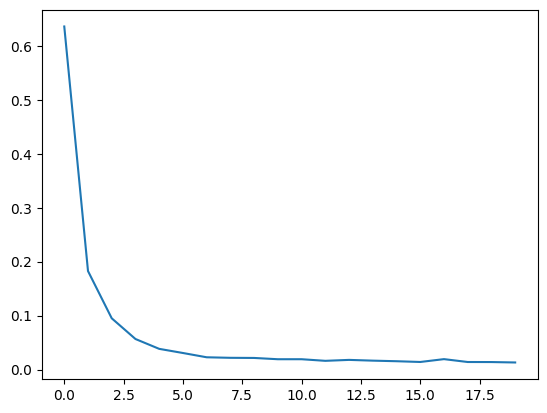

In [7]:
from tqdm import tqdm
from torch.nn.functional import mse_loss
import matplotlib.pyplot as plt

epochs = 20

val_loss_history = []
train_loss_history = []

plt.figure()
for i in tqdm(range(epochs)):
    model.train()

    train_loss = 0.0
    for x, y in train_loader:
        x = x.to(device)
        y = y.to(device)
        out = model(x)
        loss = mse_loss(out, y)
        
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        train_loss += loss.item() * x.size(0)
    train_loss_history.append(train_loss)
    
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for x, y in val_loader:
            x = x.to(device)
            y = y.to(device)
            
            out = model(x)
            loss = mse_loss(out, y)
            val_loss += loss.item() * x.size(0)

    val_loss_history.append(val_loss)
    
    plt.clf()
    plt.plot(val_loss_history, label='validation loss')
    plt.plot(train_loss, label='train loss')

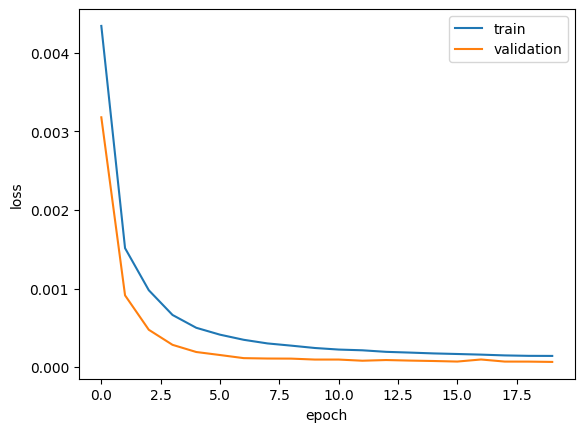

In [15]:
plt.figure()
plt.plot(np.array(train_loss_history) / len(train_ds), label='train')
plt.plot(np.array(val_loss_history) / len(val_ds), label='validation')
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend()

In [9]:
model.eval()
test_loss = 0.0
with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        y = y.to(device)
        
        out = model(x)
        loss = mse_loss(out, y)
        test_loss += loss.item() * x.size(0)

In [10]:
print("train loss: ", train_loss_history[-1] / len(train_ds))
print("test loss: ", test_loss / len(test_ds))

train loss:  0.0001418191388282659
test loss:  7.062064163619652e-05
